# NSL23 leakage-resistant CNN temporal benchmark

This notebook reproduces the **frozen primary analysis** comparing a single-frame CNN, CNN–BiLSTM, and CNN–Transformer on the public NSL23 Nepali Sign Language alphabet videos. The primary set contains only original, individually labeled clips. Aggregate recordings are excluded because the release provides no gesture timestamps, and cropped/preprocessed derivatives are excluded to avoid source duplication.

The evaluation uses two complete 49-class signer-held-out folds (S1 and S2), three fixed seeds, 30 fixed epochs, and no validation-driven model selection. Read `PROTOCOL.md` before running. The notebook works from the supplied project folder locally or from the accompanying `NSL23_reproducibility_bundle.zip` in Google Colab.

**Compute/storage:** the official archives total about 9.6 GB and expand to about 9.7 GB. The 16-frame cache requires about 0.9 GB. A full 18-run matrix can take several hours depending on hardware.


## 1. Runtime mode and user controls

`RUN_DOWNLOAD`, `RUN_PREPARE`, `RUN_SMOKE_TEST`, and `RUN_FULL_MATRIX` are deliberately explicit and disabled by default. Full results are resumable: an existing `metrics.json` causes that run to be skipped.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, platform

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path("/content/NSL23_project") if IN_COLAB else Path.cwd()
RUN_DOWNLOAD = False          # Set True only after confirming ~22 GB free disk space.
RUN_PREPARE = False           # Build manifest, signer folds, and 16-frame cache.
RUN_SMOKE_TEST = False
RUN_FULL_MATRIX = False       # 18 runs: 3 architectures × 2 folds × 3 seeds.
RUN_BENCHMARKS = False        # Requires completed checkpoints.

print({"in_colab": IN_COLAB, "project_root": str(PROJECT_ROOT), "python": platform.python_version()})


{'in_colab': False, 'project_root': '/Users/swat/Downloads/NSL_paper', 'python': '3.11.14'}


## 2. Colab project setup

In Colab, upload `NSL23_reproducibility_bundle.zip` when prompted. This small bundle contains source code, configurations, the frozen protocol, and audit metadata—not the 10 GB dataset. Local users can skip this cell when the notebook is in the project root.


In [2]:
if IN_COLAB:
    from google.colab import files
    import zipfile
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    if not (PROJECT_ROOT / "src" / "nsl23" / "train.py").exists():
        uploaded = files.upload()
        bundle_name = next((name for name in uploaded if name.endswith(".zip")), None)
        if bundle_name is None:
            raise RuntimeError("Upload NSL23_reproducibility_bundle.zip")
        with zipfile.ZipFile(bundle_name) as archive:
            archive.extractall(PROJECT_ROOT)
    os.chdir(PROJECT_ROOT)
else:
    os.chdir(PROJECT_ROOT)

assert Path("src/nsl23/train.py").is_file(), "Run from the project root or upload the bundle."
print("Project ready:", Path.cwd())


Project ready: /Users/swat/Downloads/NSL_paper


## 3. Install and record the environment

Colab keeps its CUDA-enabled PyTorch build; the remaining packages are pinned in `requirements-colab.txt`. The local reference environment is pinned in `requirements.txt`. Hardware and library versions are recorded inside every checkpoint and run directory.


In [3]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)

import torch, torchvision, numpy, pandas, sklearn, av
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "scikit_learn": sklearn.__version__,
    "pyav": av.__version__,
    "device": device,
}
print(json.dumps(environment, indent=2))


{
  "python": "3.11.14",
  "platform": "macOS-26.3.1-arm64-arm-64bit",
  "torch": "2.13.0",
  "torchvision": "0.28.0",
  "numpy": "2.4.6",
  "pandas": "3.0.5",
  "scikit_learn": "1.9.0",
  "pyav": "18.1.0",
  "device": "mps"
}


## 4. Download and verify the official NSL23 release

The files come from Zenodo record [10478554](https://zenodo.org/records/10478554), DOI `10.5281/zenodo.10478554`, licensed CC BY 4.0. Downloads are resumed with HTTP range requests and are rejected unless both byte length and MD5 match the audited record.


In [4]:
from urllib.parse import quote
import hashlib, requests

RAW_DIR = Path("data/raw_archives")
EXTRACTED_DIR = Path("data/extracted")
RAW_DIR.mkdir(parents=True, exist_ok=True)
audit = json.loads(Path("artifacts/audit/archive_checksums.json").read_text())

def md5_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.md5(usedforsecurity=False)
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download_resumable(url, destination, expected_bytes):
    destination = Path(destination)
    existing = destination.stat().st_size if destination.exists() else 0
    if existing > expected_bytes:
        destination.unlink()
        existing = 0
    if existing == expected_bytes:
        return
    headers = {"Range": f"bytes={existing}-"} if existing else {}
    mode = "ab" if existing else "wb"
    with requests.get(url, headers=headers, stream=True, timeout=120) as response:
        response.raise_for_status()
        if existing and response.status_code != 206:
            existing, mode = 0, "wb"
        with destination.open(mode) as handle:
            for chunk in response.iter_content(8 * 1024 * 1024):
                if chunk:
                    handle.write(chunk)
    if destination.stat().st_size != expected_bytes:
        raise IOError(f"Size mismatch for {destination.name}")

if RUN_DOWNLOAD:
    for item in audit["files"]:
        destination = Path("Details Dataset.docx") if item["name"].endswith(".docx") else RAW_DIR / item["name"]
        url = f"https://zenodo.org/records/10478554/files/{quote(item['name'])}?download=1"
        download_resumable(url, destination, int(item["bytes"]))
        observed = md5_file(destination)
        if observed != item["md5"]:
            raise IOError(f"MD5 mismatch for {destination.name}: {observed}")
        print("verified", destination.name)
else:
    print("Download disabled. Set RUN_DOWNLOAD=True when needed.")


Download disabled. Set RUN_DOWNLOAD=True when needed.


## 5. Extract archives safely

The extraction check prevents path traversal. Re-running this cell is idempotent for already extracted files.


In [5]:
import zipfile

def safe_extract(zip_path, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if destination not in target.parents and target != destination:
                raise RuntimeError(f"Unsafe archive member: {member.filename}")
        archive.extractall(destination)

if RUN_PREPARE:
    EXTRACTED_DIR.mkdir(parents=True, exist_ok=True)
    for item in audit["files"]:
        if item["name"].endswith(".zip"):
            archive = RAW_DIR / item["name"]
            if archive.stat().st_size != int(item["bytes"]) or md5_file(archive) != item["md5"]:
                raise IOError(f"Archive is absent or unverified: {archive}")
            safe_extract(archive, EXTRACTED_DIR)
            print("extracted", archive.name)
else:
    print("Preparation disabled. Set RUN_PREPARE=True after verified downloads exist.")


Preparation disabled. Set RUN_PREPARE=True after verified downloads exist.


## 6. Build the lossless manifest and frozen signer folds

This stage probes every video, canonicalizes the documented 49-class label order, excludes aggregate/cropped inputs from the primary set, and creates the S1- and S2-held-out folds. Each fold must contain 277 training clips and 98 test clips, with every class represented on both sides.


In [6]:
env = os.environ.copy()
env["PYTHONPATH"] = str(Path("src").resolve())

def run(command):
    print("$", " ".join(map(str, command)))
    subprocess.run(list(map(str, command)), check=True, env=env)

if RUN_PREPARE:
    run([sys.executable, "-m", "nsl23.manifest", EXTRACTED_DIR,
         "--output", "data/manifests/nsl23_manifest_all.csv",
         "--summary", "artifacts/audit/nsl23_manifest_summary.json"])
    run([sys.executable, "-m", "nsl23.folds",
         "--manifest", "data/manifests/nsl23_manifest_all.csv",
         "--output-dir", "data/manifests/folds",
         "--summary", "artifacts/audit/isolated_twofold_summary.json"])


## 7. Cache 16 frame-bin centers per clip

Frames are decoded once with PyAV, sampled at temporal-bin centers, resized without distorting aspect ratio, letterboxed to 224×224, and stored as unsigned 8-bit NumPy arrays. Both fold manifests refer to the same 375 cache files.


In [7]:
if RUN_PREPARE:
    for fold in ["heldout_s1", "heldout_s2"]:
        run([sys.executable, "-m", "nsl23.frame_cache",
             f"data/manifests/folds/{fold}.csv",
             "--output-dir", "data/frame_cache_primary",
             "--updated-manifest", f"data/manifests/folds/{fold}_cached.csv",
             "--num-frames", "16", "--image-size", "224"])
    run([sys.executable, "scripts/verify_primary_protocol.py"])


## 8. One-epoch software smoke test

The smoke test checks all three forward/backward paths and artifact exports. Its scores are not scientific results. It uses only fold S1 and one seed, limits training to one epoch, and uses 20 bootstrap replicates to keep the check short.


In [8]:
if RUN_SMOKE_TEST:
    run([sys.executable, "scripts/run_primary_experiments.py",
         "--output-dir", "artifacts/smoke/notebook",
         "--folds", "heldout_s1",
         "--models", "single_frame_cnn", "cnn_bilstm", "cnn_transformer",
         "--seeds", "73", "--max-epochs", "1", "--bootstrap-replicates", "20"])


## 9. Full frozen experiment matrix

Do not modify the configuration after inspecting test results. The experiment runner trains each architecture for exactly 30 epochs and evaluates the held-out signer once after the final checkpoint is fixed. The class-weighted loss is computed from training counts only.


In [9]:
if RUN_FULL_MATRIX:
    run([sys.executable, "scripts/run_primary_experiments.py", "--output-dir", "artifacts/runs/primary"])
else:
    print("Full matrix disabled. Set RUN_FULL_MATRIX=True to reproduce all 18 runs.")


Full matrix disabled. Set RUN_FULL_MATRIX=True to reproduce all 18 runs.


## 10. Validate, aggregate, and plot results

Aggregation fails closed unless all 18 run identities, 30-epoch histories, and 98 held-out predictions per run are present. The two held-out folds are pooled within each seed (196 clips), then mean and sample SD are reported across the three seeds. Sample-level bootstrap intervals are descriptive and do not estimate signer-population uncertainty from only two test signers.


In [10]:
if Path("artifacts/runs/primary").exists() and len(list(Path("artifacts/runs/primary").glob("**/metrics.json"))) == 18:
    run([sys.executable, "scripts/summarize_primary_results.py"])
    run([sys.executable, "scripts/generate_publication_figures.py"])
    display(pandas.read_csv("artifacts/results/model_summary.csv"))
else:
    print("Complete the 18-run matrix before aggregation.")


$ /Users/swat/Downloads/NSL_paper/.venv/bin/python scripts/summarize_primary_results.py


{
  "status": "pass",
  "expected_runs": 18,
  "completed_runs": 18,
  "models": [
    "single_frame_cnn",
    "cnn_bilstm",
    "cnn_transformer"
  ],
  "folds": [
    "heldout_s1",
    "heldout_s2"
  ],
  "seeds": [
    17,
    42,
    73
  ],
  "unique_heldout_clips_per_seed": 196,
  "bootstrap_replicates_per_pooled_seed": 2000,
  "bootstrap_note": "Intervals are class-stratified, sample-level descriptive intervals; with two held-out signers they do not estimate population-level signer uncertainty.",
  "model_summary": [
    {
      "model": "cnn_bilstm",
      "replicates": 3,
      "accuracy_mean": 0.06972789115646259,
      "accuracy_sd": 0.02124148979047074,
      "accuracy_min": 0.04591836734693878,
      "accuracy_max": 0.08673469387755102,
      "macro_precision_mean": 0.05197948987597917,
      "macro_precision_sd": 0.050074552141593086,
      "macro_precision_min": 0.019017782551617138,
      "macro_precision_max": 0.10960162645299462,
      "macro_recall_mean": 0.069727891

{"status": "pass", "figures": 7, "output_dir": "artifacts/figures"}


,model,replicates,accuracy_mean,accuracy_sd,accuracy_min,accuracy_max,macro_precision_mean,macro_precision_sd,macro_precision_min,macro_precision_max,...,macro_recall_min,macro_recall_max,macro_f1_mean,macro_f1_sd,macro_f1_min,macro_f1_max,weighted_f1_mean,weighted_f1_sd,weighted_f1_min,weighted_f1_max
0,cnn_bilstm,3,0.069728,0.021241,0.045918,0.086735,0.051979,0.050075,0.019018,0.109602,...,0.045918,0.086735,0.041564,0.021395,0.023144,0.065031,0.041564,0.021395,0.023144,0.065031
1,cnn_transformer,3,0.062925,0.007793,0.056122,0.071429,0.057247,0.016355,0.043797,0.075452,...,0.056122,0.071429,0.043933,0.012900,0.031623,0.057351,0.043933,0.012900,0.031623,0.057351
2,single_frame_cnn,3,0.057823,0.007793,0.051020,0.066327,0.035816,0.005902,0.031166,0.042456,...,0.051020,0.066327,0.035281,0.002153,0.032950,0.037196,0.035281,0.002153,0.032950,0.037196


figure_1_study_flow.png


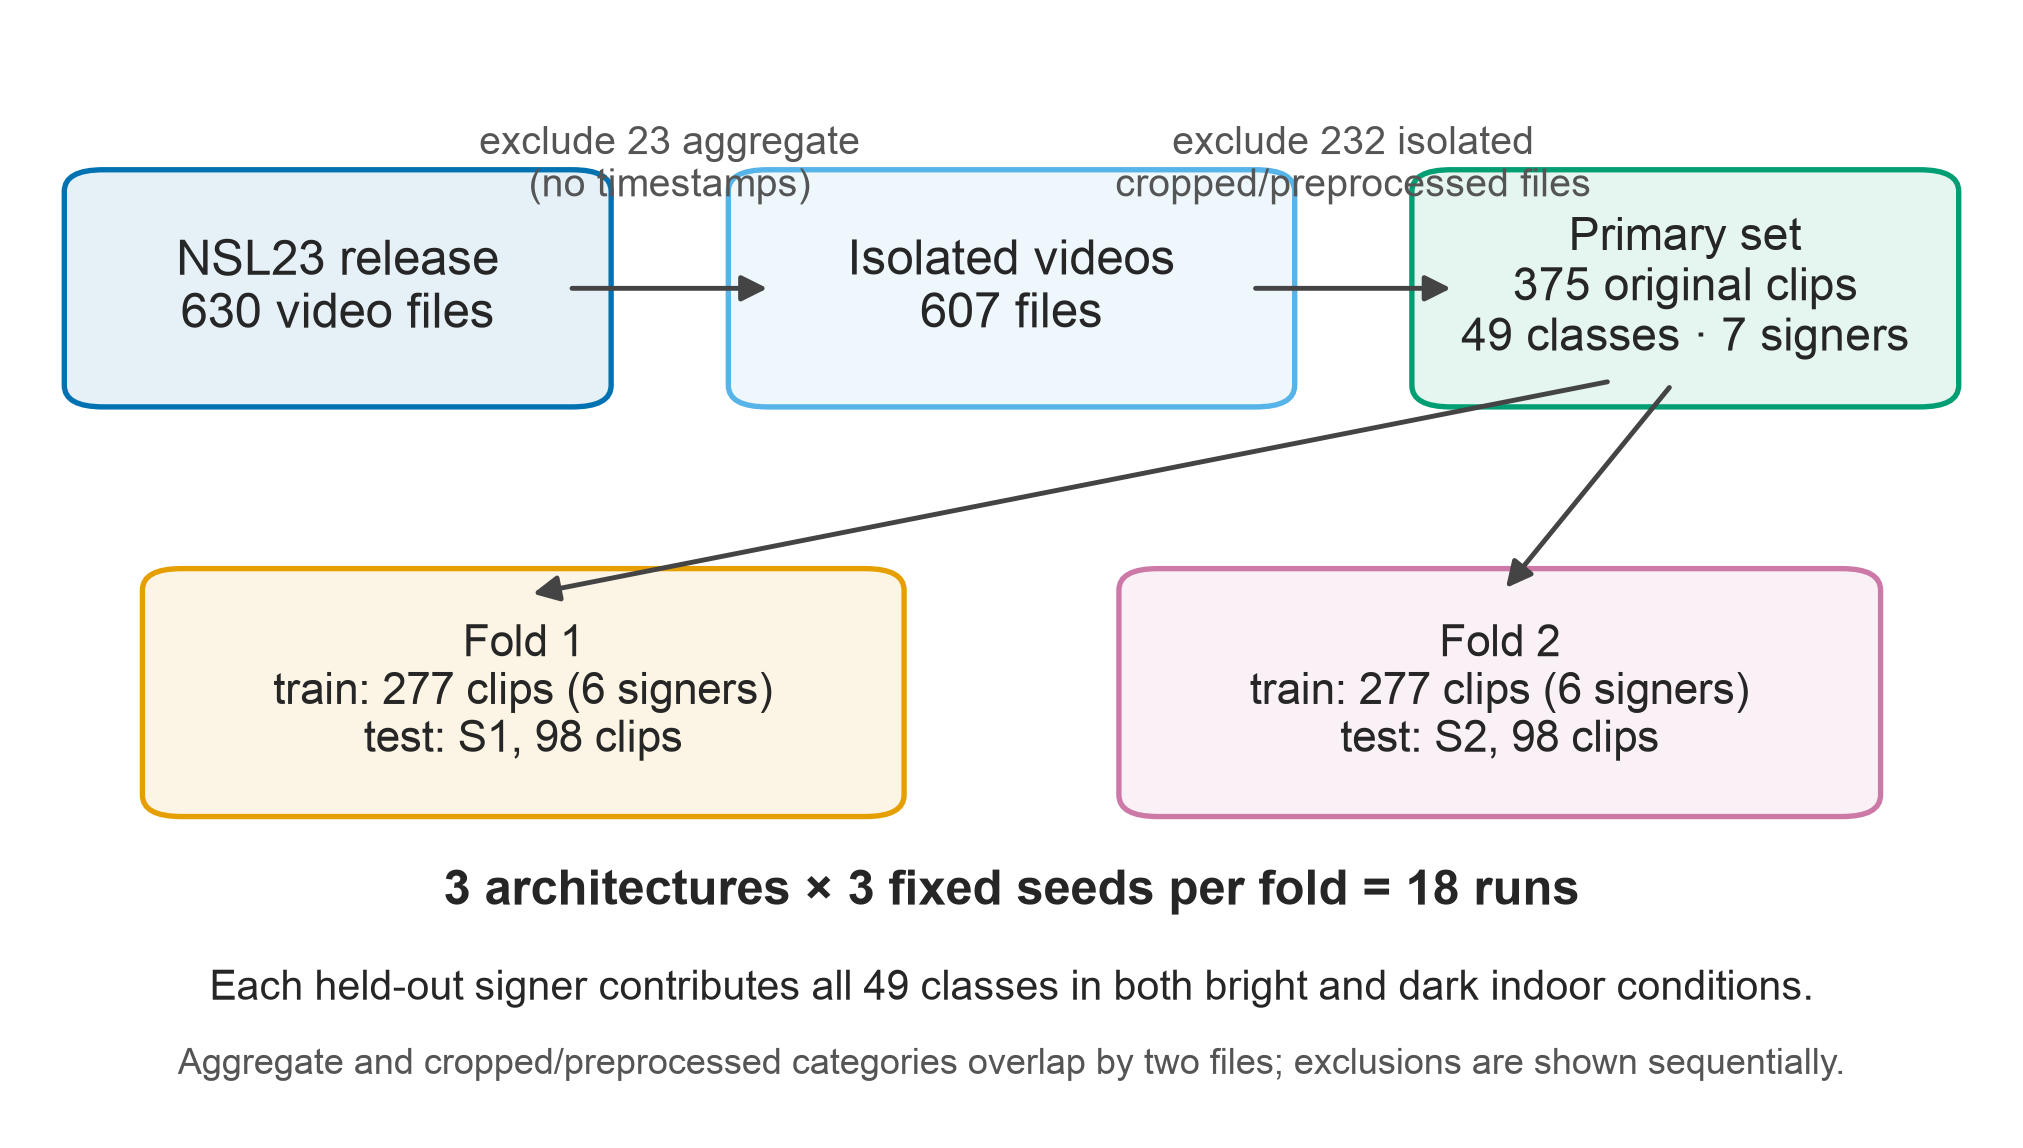

figure_2_architectures.png


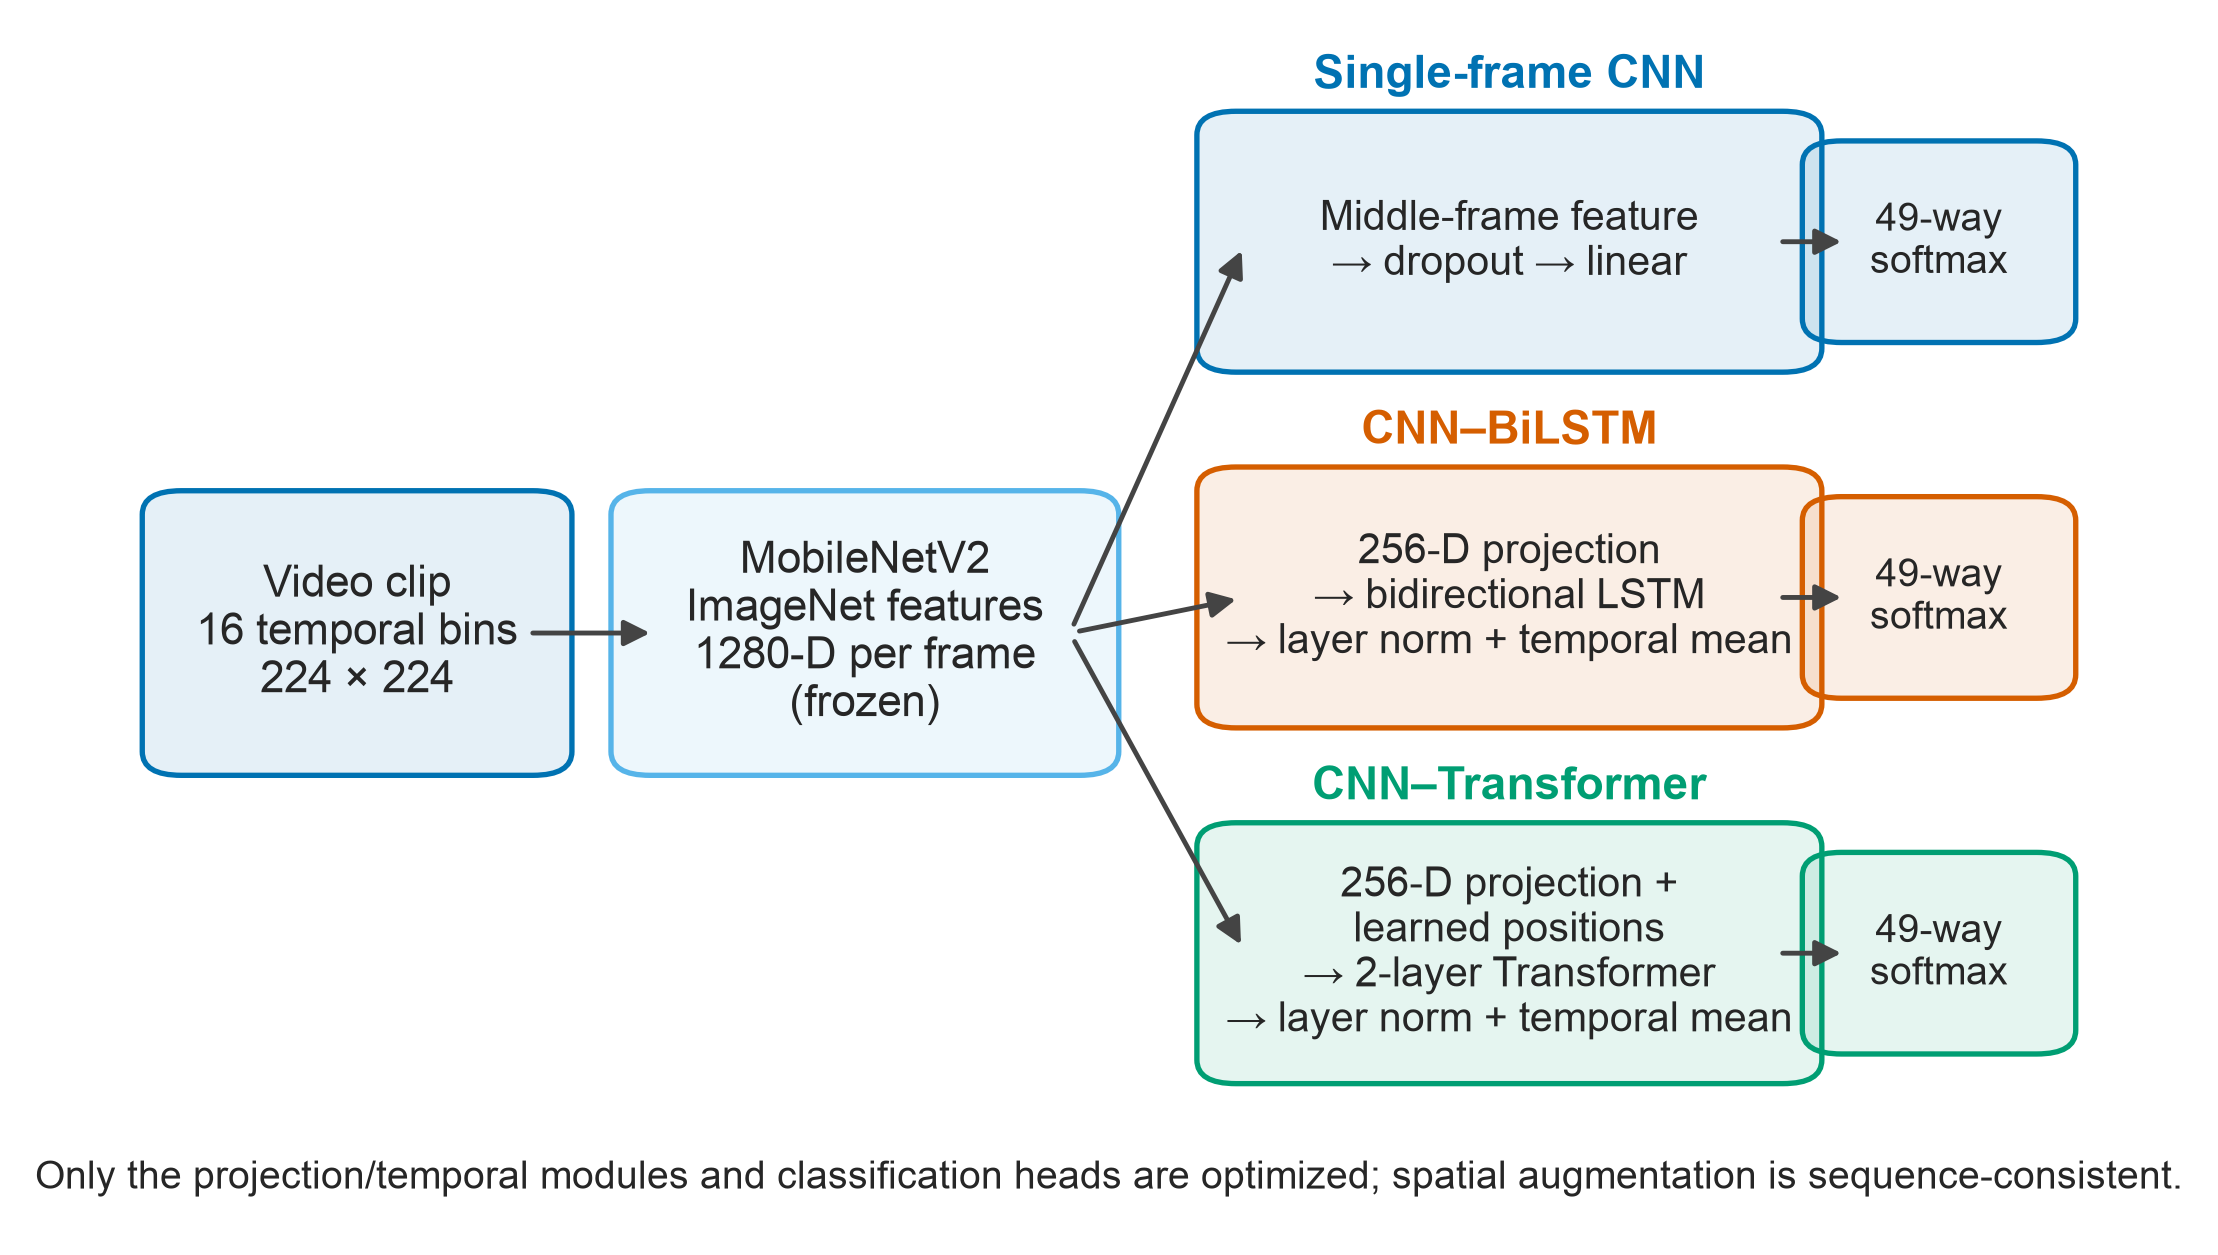

figure_3_primary_performance.png


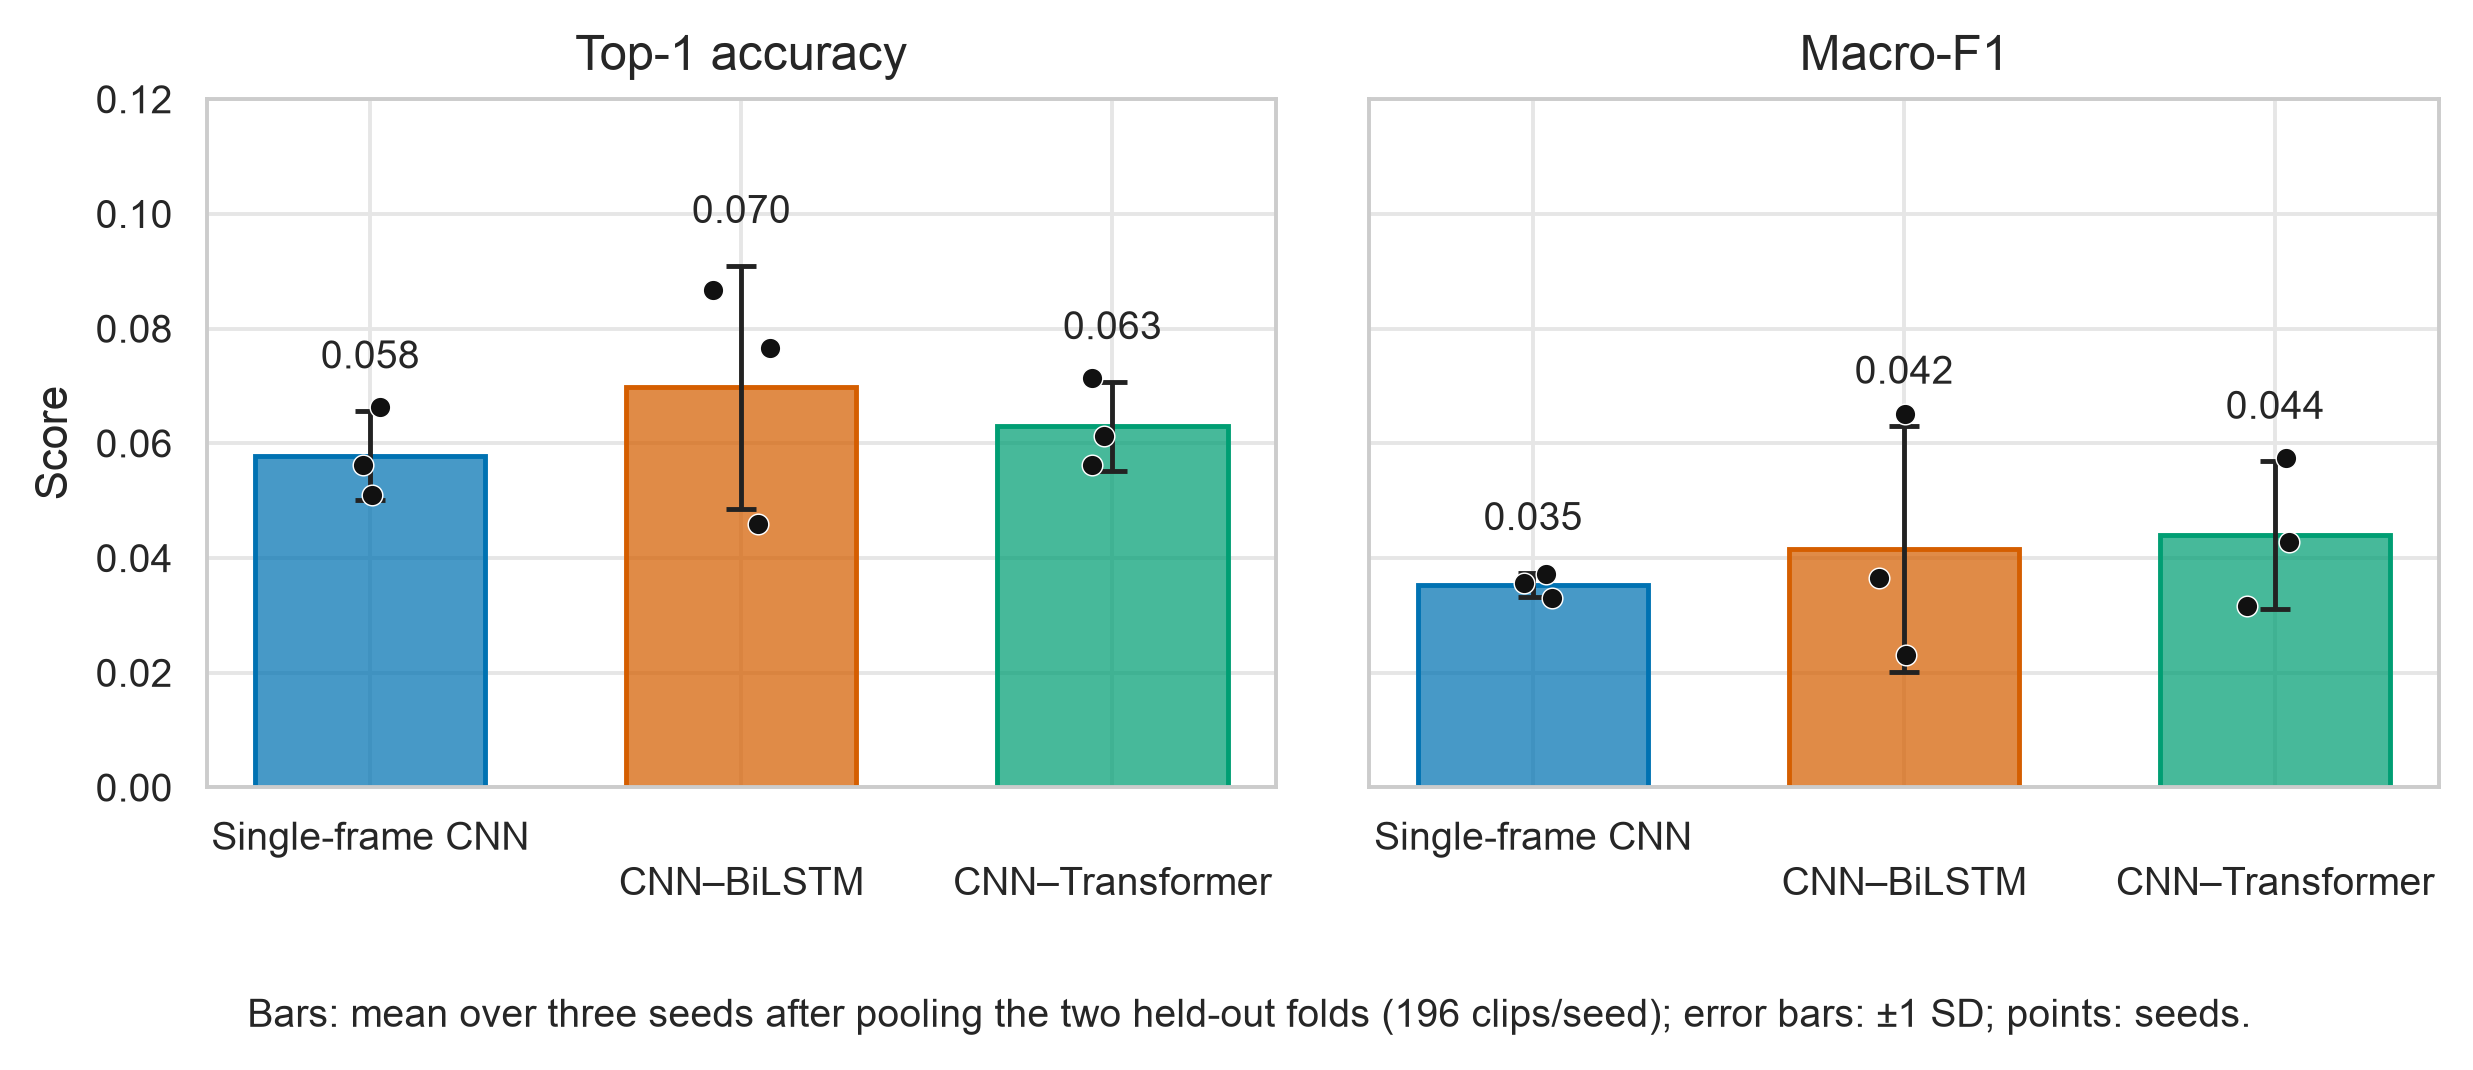

figure_4_training_curves.png


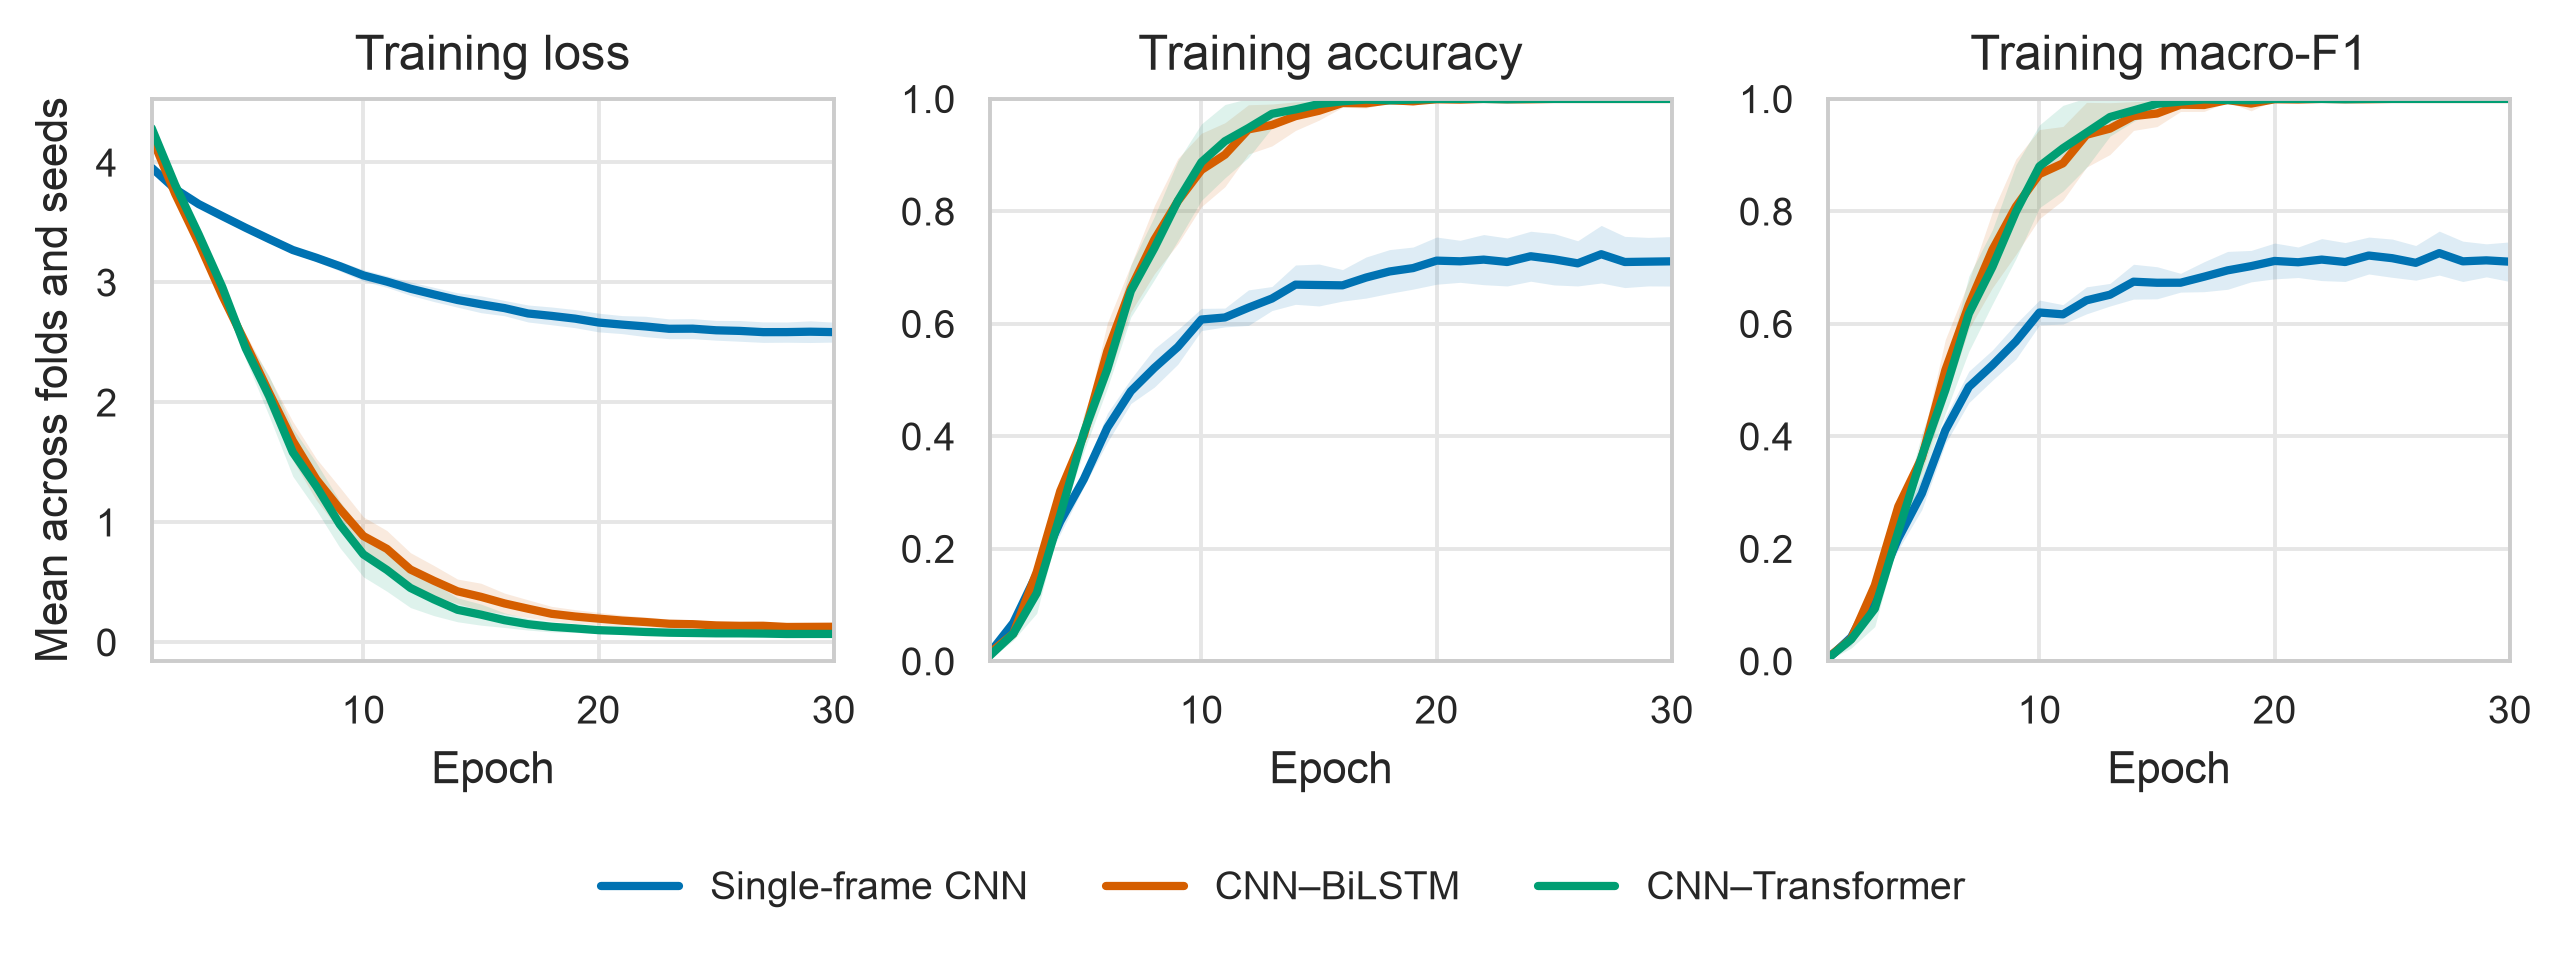

figure_5_lighting_performance.png


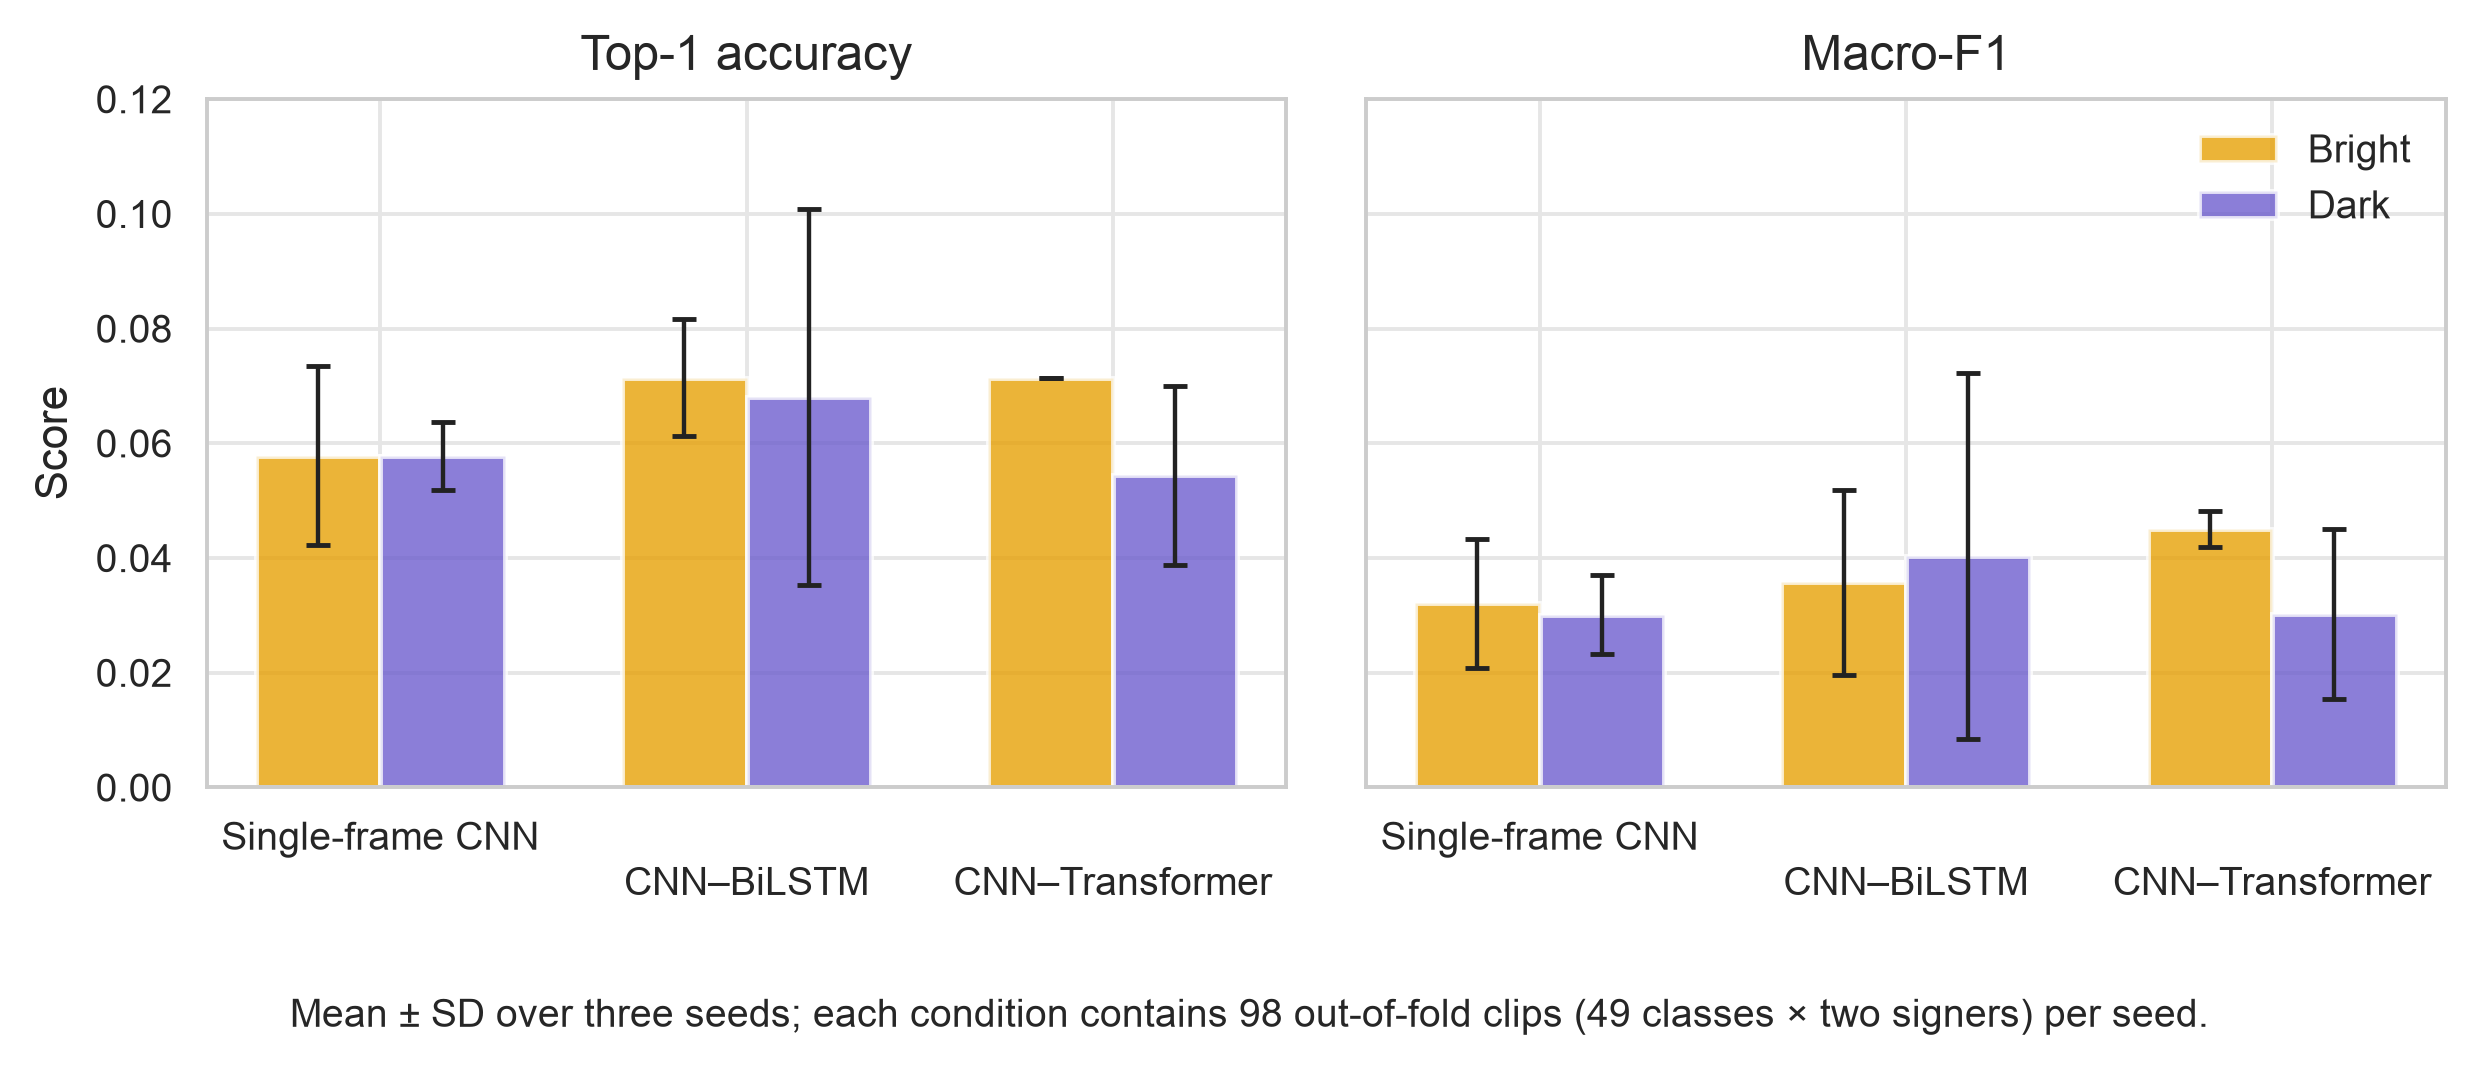

figure_6_transformer_confusion.png


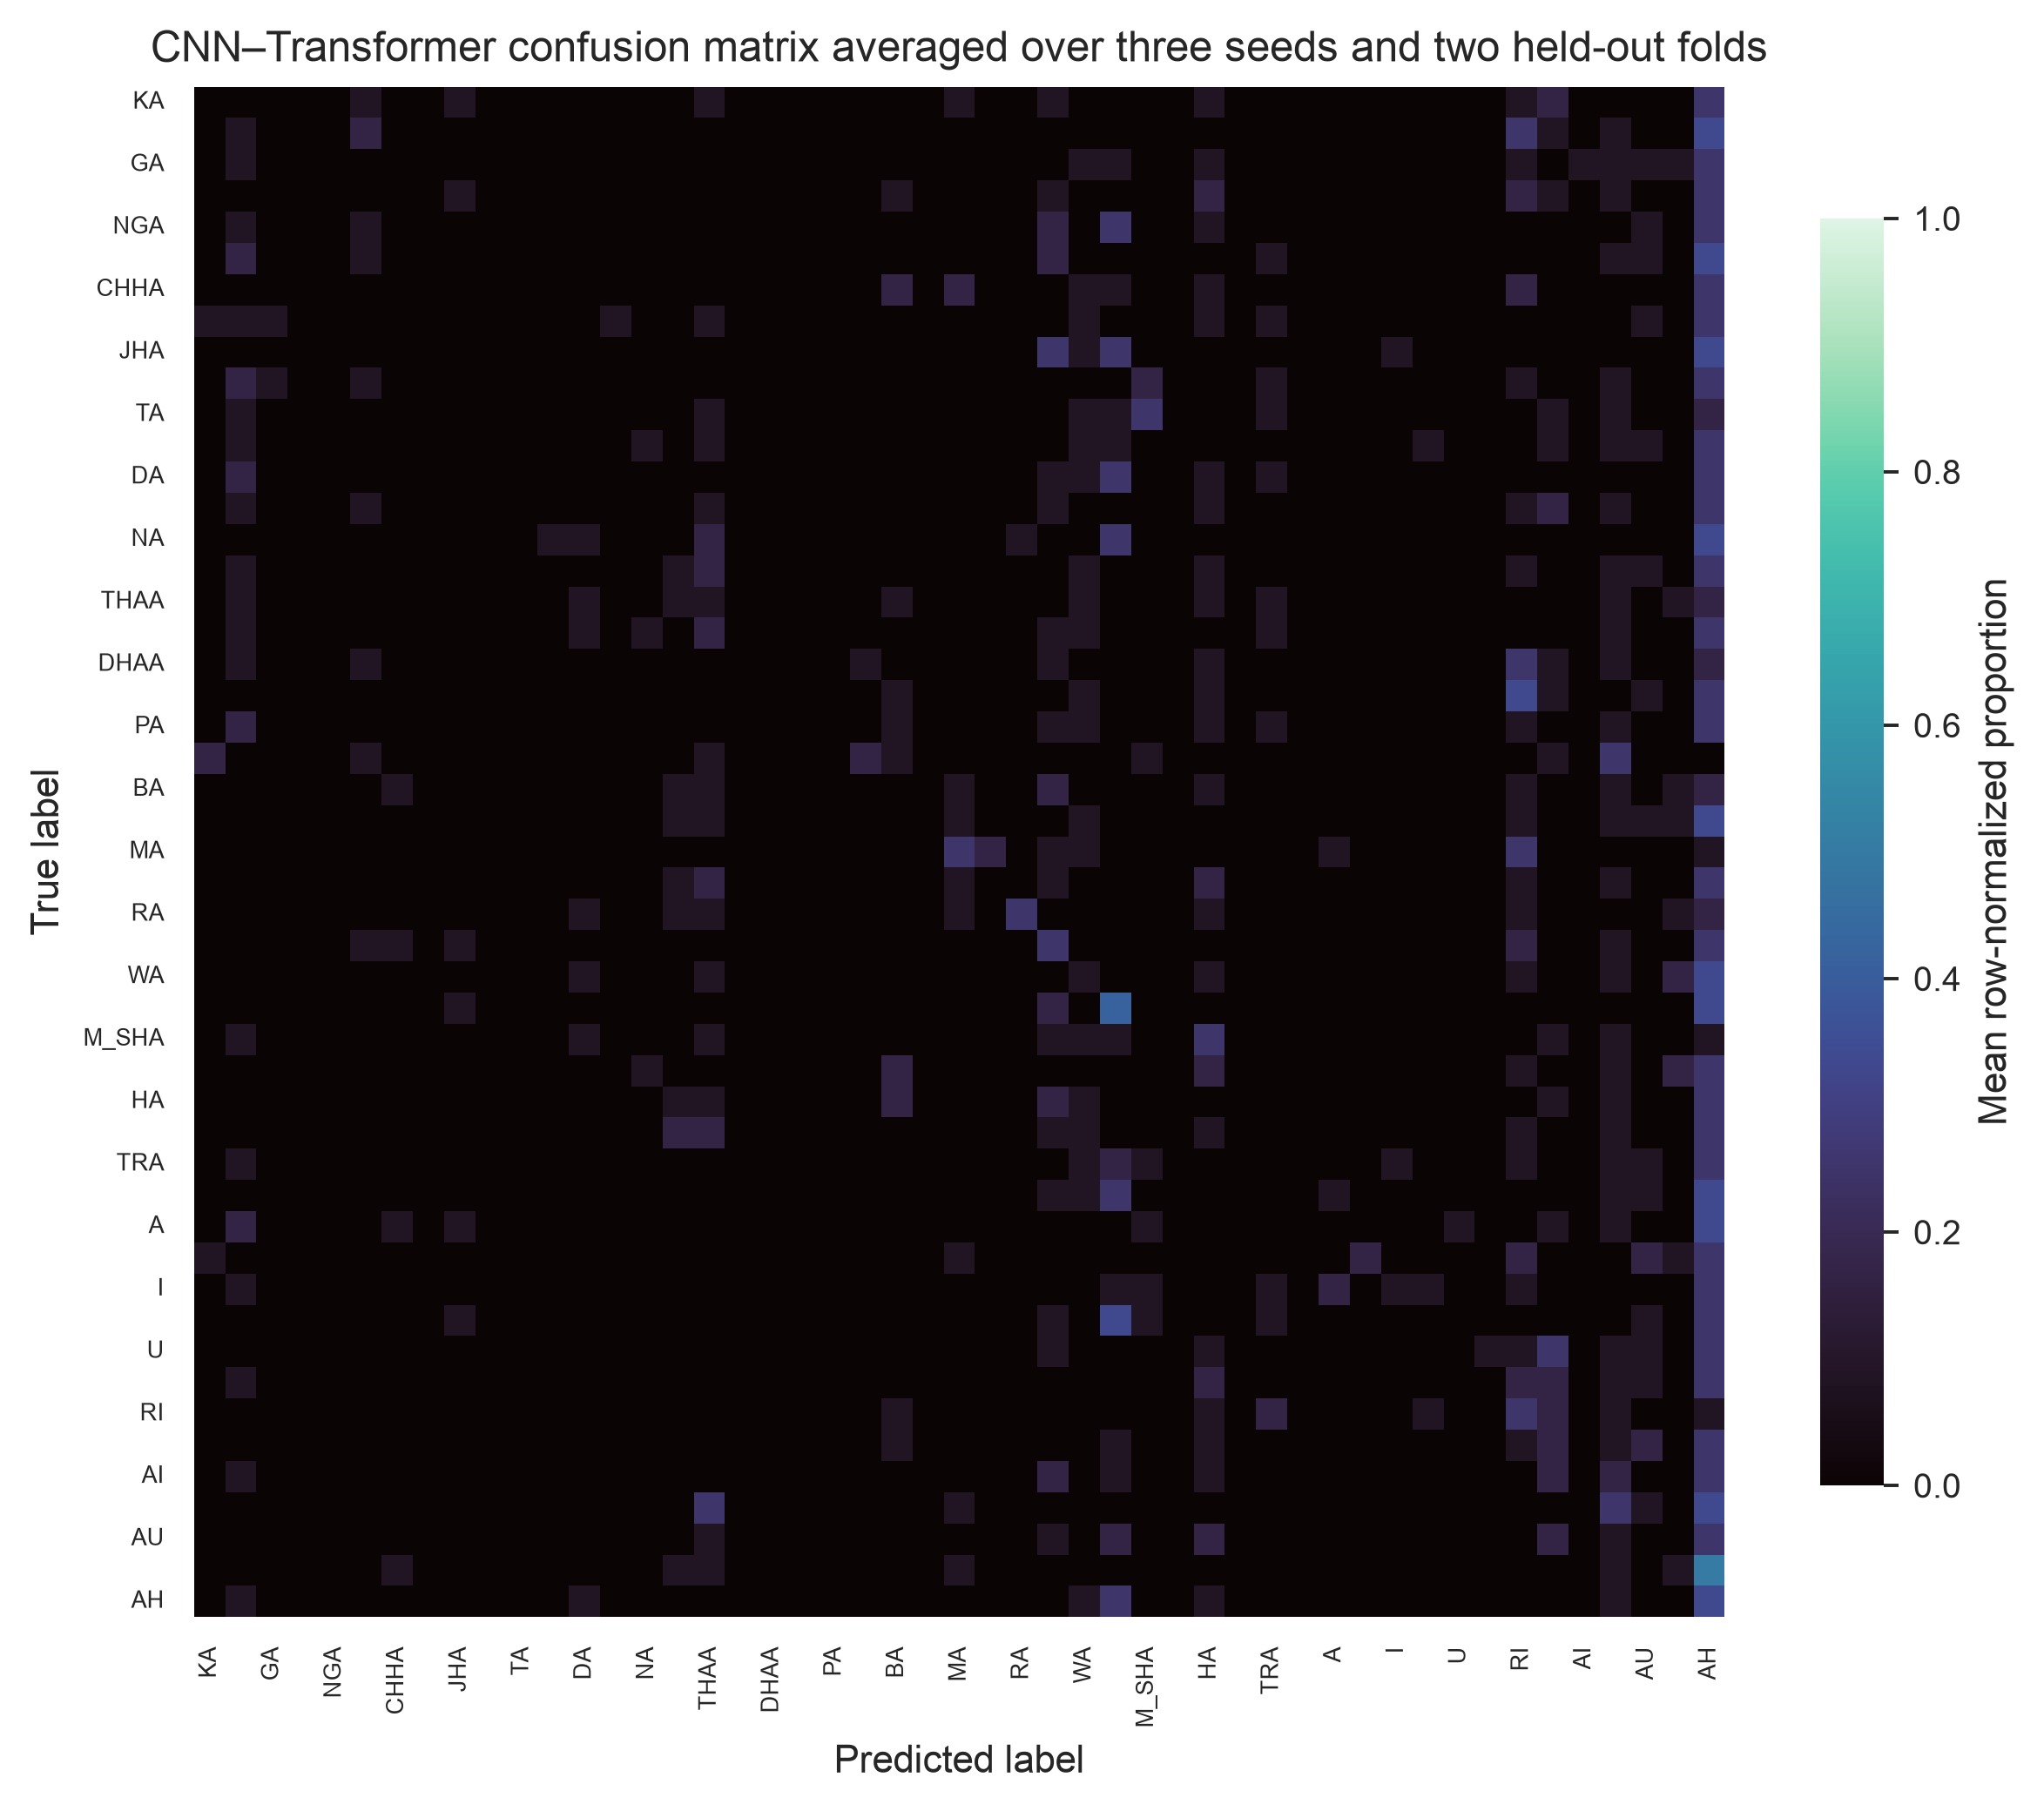

figure_7_transformer_per_class_recall.png


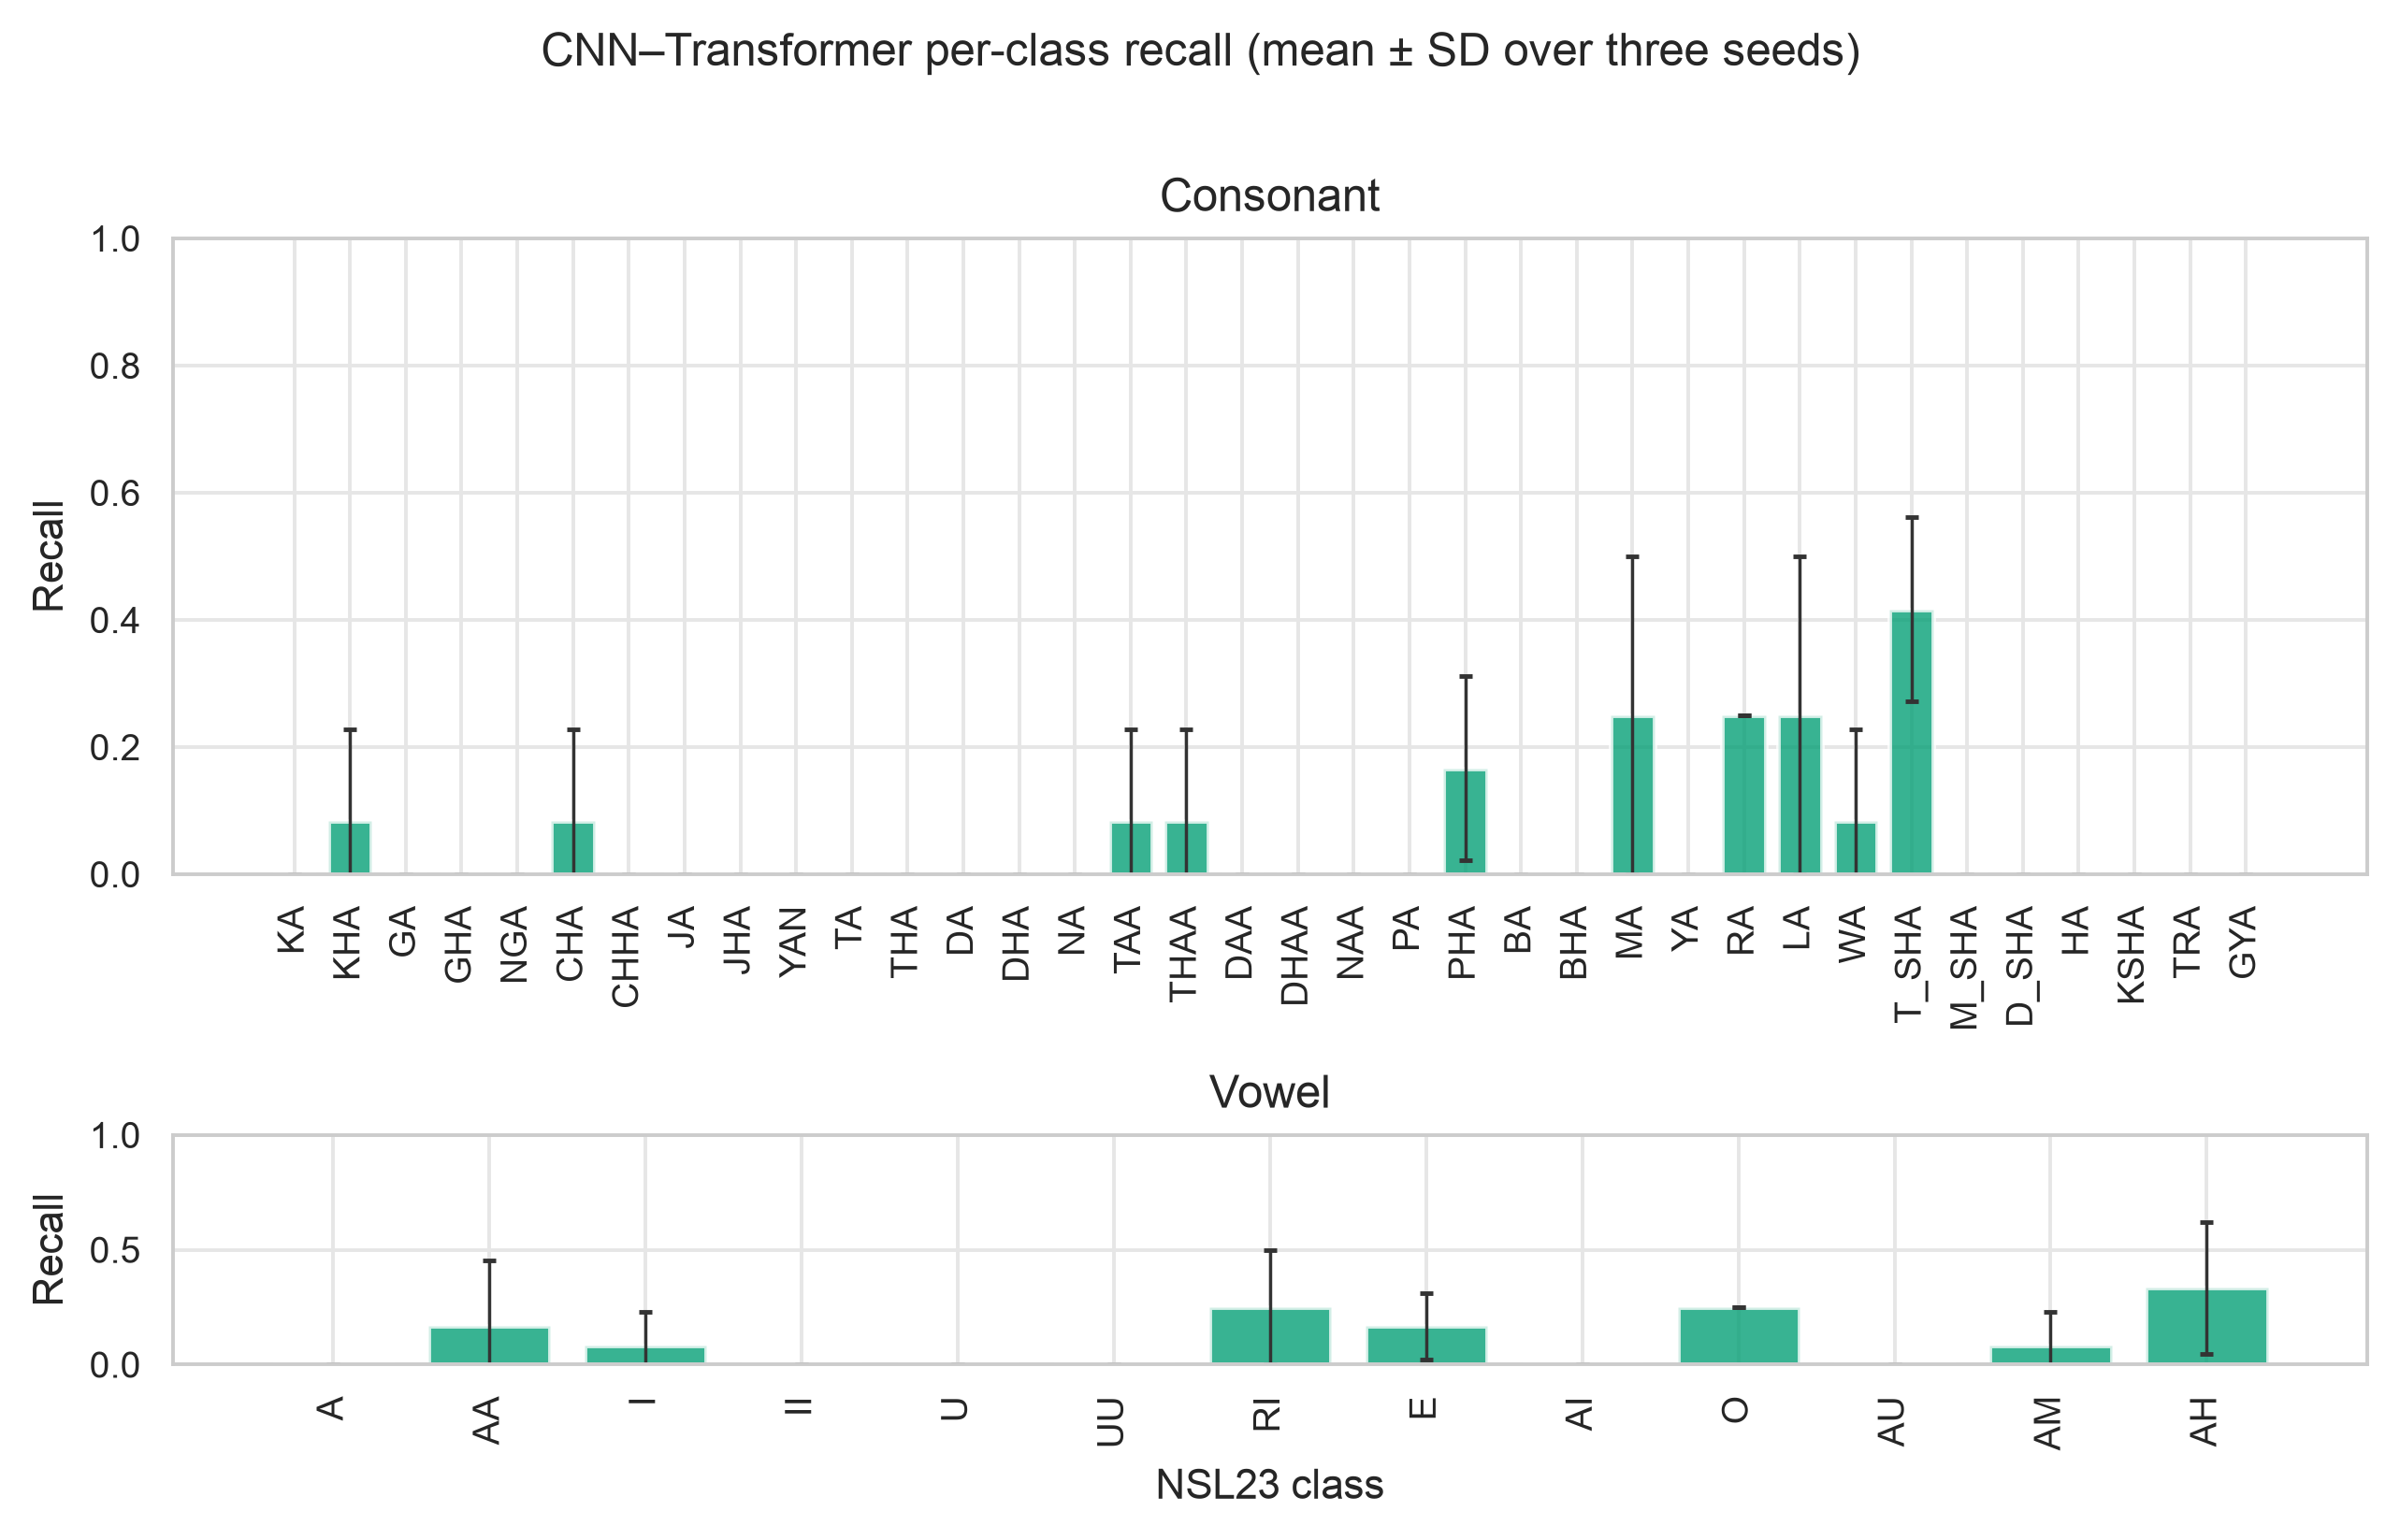

In [11]:
from IPython.display import Image, display
for figure in sorted(Path("artifacts/figures").glob("figure_[1-7]*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=900))


## 11. Batch-one runtime benchmark

The benchmark reports two explicitly synchronized quantities: model-only forward/softmax latency from a device-resident normalized tensor, and end-to-end latency from opening an original video through prediction. It uses one fixed completed checkpoint per architecture; latency is an implementation/hardware measurement, not a test-set selection criterion.


In [12]:
if RUN_BENCHMARKS:
    run([sys.executable, "scripts/run_runtime_benchmarks.py"])


## 12. Export a compact result archive

Checkpoints are intentionally omitted from this compact archive because they are large; the archived CSV/JSON/PDF/PNG files are sufficient to audit reported tables and figures. Keep the project folder to preserve checkpoints.


In [13]:
import shutil
export_root = Path("artifacts")
if (export_root / "results").exists():
    archive = shutil.make_archive("NSL23_primary_results", "zip", root_dir=export_root,
                                  base_dir="results")
    print("Created", archive)


Created /Users/swat/Downloads/NSL_paper/NSL23_primary_results.zip


## Interpretation boundary

This benchmark estimates performance on two held-out signers under the two indoor lighting conditions available as complete 49-class tests. It does **not** establish generalization to the wider signer population, prepared backgrounds, outdoor scenes, continuous signing, or real-time deployment. Aggregate recordings remain auditable source material but are outside the primary analysis until trustworthy gesture timestamps are available.
